In [74]:
import os
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import plotly.express as px
import numpy as np
import math

In [75]:
happiness_df = pd.read_csv("../../data/processed/world_happiness_2015_2019_clean.csv")


## 1. Mathematical Formula of Skewness

The skewness coefficient measures the degree of asymmetry in a probability distribution relative to its mean.

The population skewness formula is:

$$
\text{Skewness} = \frac{E[(X-\mu)^3]}{\sigma^3}
$$

In [76]:
# Calculate skewness for numerical variables
skewness = happiness_df.select_dtypes(
    include="number"
).skew()

# Display results
print(skewness.sort_values(ascending=False))

perceptions_of_corruption    1.515219
generosity                   1.044360
happiness_score              0.035859
year                         0.005904
happiness_rank               0.000497
gdp_per_capita              -0.318581
healthy_life_expectancy     -0.501203
freedom                     -0.521259
social_support              -0.684632
dtype: float64


## 2. Sample Skewness Formula

$$
G_1 = \frac{n}{(n-1)(n-2)}
\sum_{i=1}^{n}
\left(\frac{x_i-\bar{x}}{s}\right)^3
$$

In [77]:
# Classify skewness levels
def classify_skewness(value):
    if value > 1:
        return "Highly positively skewed"
    elif value > 0.5:
        return "Moderately positively skewed"
    elif value < -1:
        return "Highly negatively skewed"
    elif value < -0.5:
        return "Moderately negatively skewed"
    else:
        return "Approximately symmetric"

skewness_results = pd.DataFrame({
    "Skewness": skewness,
    "Distribution": skewness.apply(classify_skewness)
})

display(skewness_results)

,Skewness,Distribution
year,0.005904,Approximately symmetric
happiness_rank,0.000497,Approximately symmetric
happiness_score,0.035859,Approximately symmetric
gdp_per_capita,-0.318581,Approximately symmetric
social_support,-0.684632,Moderately negatively skewed
healthy_life_expectancy,-0.501203,Moderately negatively skewed
freedom,-0.521259,Moderately negatively skewed
generosity,1.044360,Highly positively skewed
perceptions_of_corruption,1.515219,Highly positively skewed


# 3. Visualize the Distributions

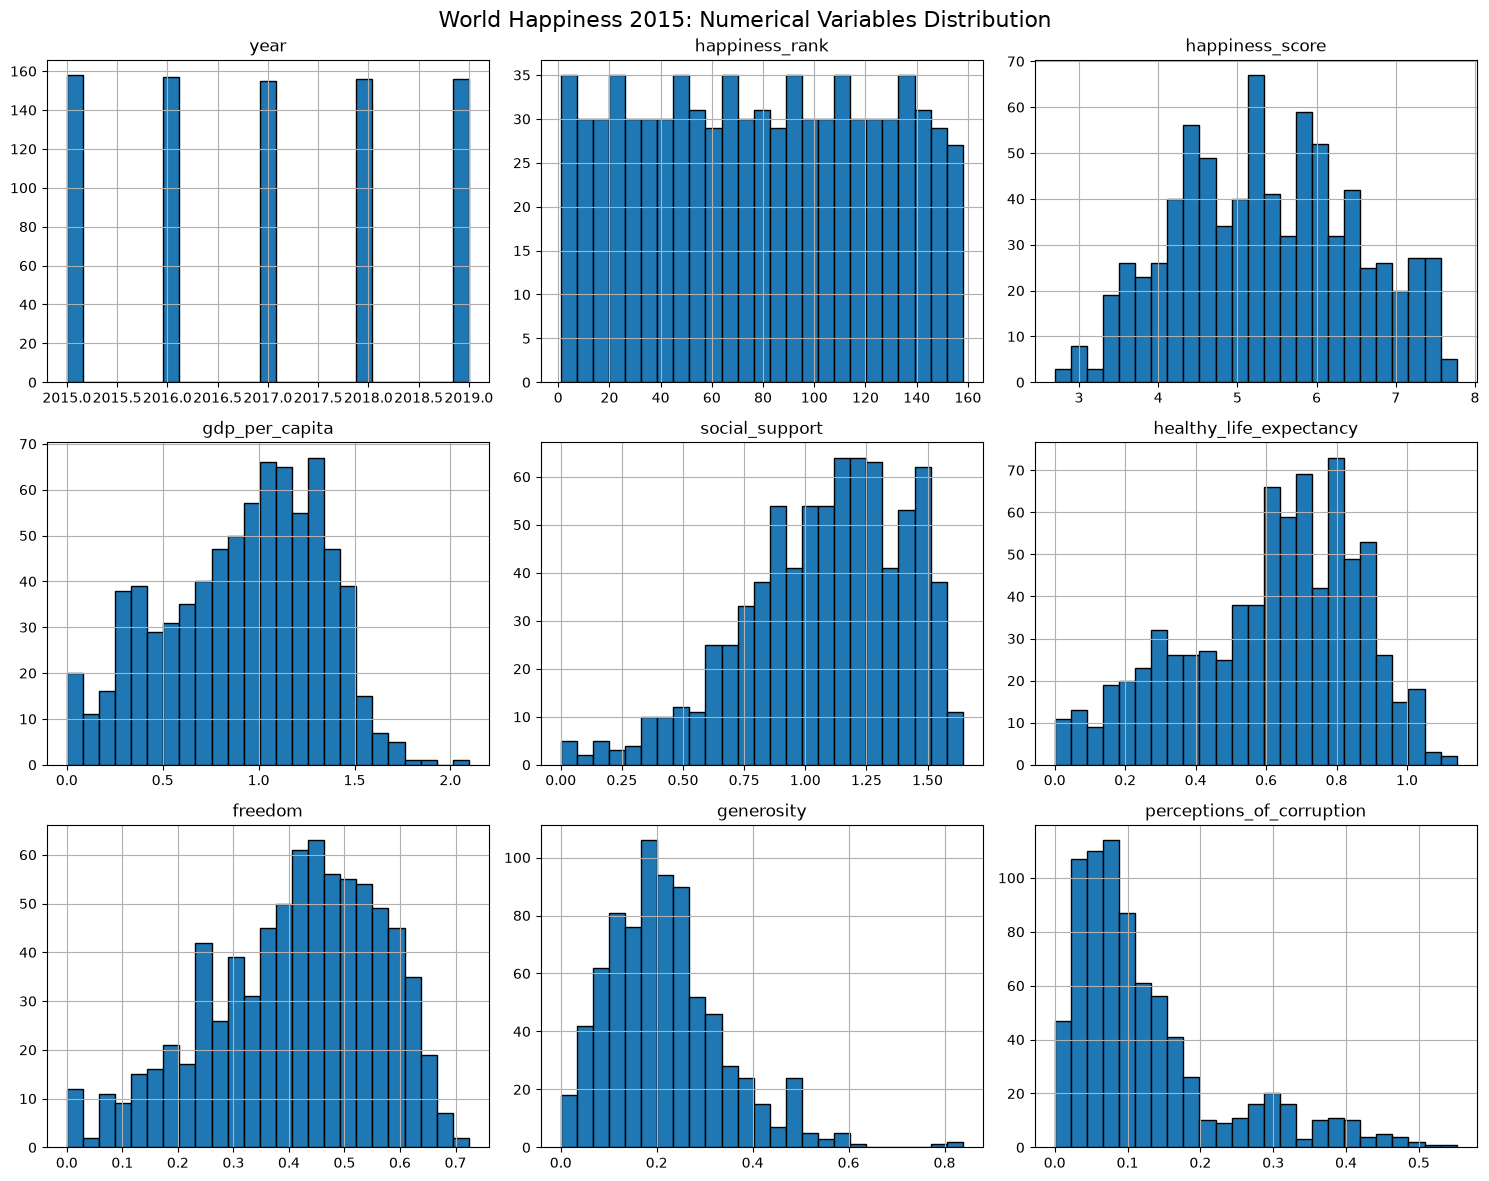

In [78]:
import matplotlib.pyplot as plt
import seaborn as sns

numerical_cols = happiness_df.select_dtypes(
    include="number"
).columns

happiness_df[numerical_cols].hist(
    figsize=(15, 12),
    bins=25,
    edgecolor="black"
)

plt.suptitle(
    "World Happiness 2015: Numerical Variables Distribution",
    fontsize=16
)

plt.tight_layout()
plt.show()

## 4. Skewness Treatment by Algorithm

The treatment of skewness depends on the assumptions and characteristics of each machine learning algorithm.

| Variable | Skewness | Distribution | Linear Regression | Random Forest | Decision Tree |
|---|---:|---|---|---|---|
| perceptions_of_corruption | 1.515 | Highly positive | Evaluate relationship and residuals | Keep original values | Keep original values |
| generosity | 1.044 | Highly positive | Evaluate relationship and residuals | Keep original values | Keep original values |
| social_support | -0.685 | Moderately negative | Evaluate relationship and residuals | Keep original values | Keep original values |
| healthy_life_expectancy | -0.501 | Moderately negative | Evaluate relationship and residuals | Keep original values | Keep original values |
| freedom | -0.521 | Moderately negative | Evaluate relationship and residuals | Keep original values | Keep original values |
| gdp_per_capita | -0.319 | Approximately symmetric | Keep original values initially | Keep original values | Keep original values |
| happiness_score | 0.036 | Approximately symmetric | Evaluate target and residual behavior | Keep original values | Keep original values |

**Note:** Skewness does not automatically require correction. Linear Regression does not require normally distributed predictors; transformations should be considered only when justified by nonlinear relationships, influential observations, or residual diagnostics. Tree-based algorithms generally handle skewed predictor distributions without requiring transformations.

In [79]:

# Load numerical variables
numeric_df = happiness_df.select_dtypes(include="number")

# Display descriptive statistics
display(numeric_df.describe().T)

,count,mean,std,min,25%,50%,75%,max
year,782.0,2016.993606,1.417364,2015.000,2016.000000,2017.000000,2018.000000,2019.000000
happiness_rank,782.0,78.698210,45.182384,1.000,40.000000,79.000000,118.000000,158.000000
happiness_score,782.0,5.379018,1.127456,2.693,4.509750,5.322000,6.189500,7.769000
gdp_per_capita,782.0,0.916047,0.407340,0.000,0.606500,0.982205,1.236187,2.096000
social_support,782.0,1.078392,0.329548,0.000,0.869363,1.124735,1.327250,1.644000
healthy_life_expectancy,782.0,0.612416,0.248309,0.000,0.440183,0.647310,0.808000,1.141000
freedom,782.0,0.411091,0.152880,0.000,0.309768,0.431000,0.531000,0.724000
generosity,782.0,0.218576,0.122321,0.000,0.130000,0.201982,0.278832,0.838075
perceptions_of_corruption,782.0,0.125599,0.105847,0.000,0.054250,0.091033,0.156243,0.551910


## 2. Detect Potential Outliers Using IQR

The Interquartile Range (IQR) is a statistical measure used to identify potential outliers in a dataset.

### Interquartile Range

$$
IQR = Q_3 - Q_1
$$

Where:

- $Q_1$: First quartile (25th percentile).
- $Q_3$: Third quartile (75th percentile).
- $IQR$: Interquartile range.

### Lower Bound

$$
Lower\ Bound = Q_1 - 1.5 \times IQR
$$

### Upper Bound

$$
Upper\ Bound = Q_3 + 1.5 \times IQR
$$

### Outlier Identification

An observation is classified as a potential outlier when:

$$
x_i < Q_1 - 1.5(IQR)
$$

or

$$
x_i > Q_3 + 1.5(IQR)
$$

Where $x_i$ represents an individual observation.

**Note:** Values outside these boundaries are considered potential outliers, not necessarily errors. They should be investigated before deciding whether to remove or transform them.

In [80]:

# Calculate quartiles
Q1 = numeric_df.quantile(0.25)
Q3 = numeric_df.quantile(0.75)

# Calculate IQR
IQR = Q3 - Q1

# Calculate outlier boundaries
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Identify potential outliers
outlier_mask = (
    (numeric_df < lower_bound) |
    (numeric_df > upper_bound)
)

# Create outlier summary
outlier_summary = pd.DataFrame({
    "Lower Bound": lower_bound,
    "Upper Bound": upper_bound,
    "Potential Outliers": outlier_mask.sum(),
    "Outlier Percentage (%)": (
        outlier_mask.sum() / len(numeric_df) * 100
    )
})

display(
    outlier_summary.sort_values(
        "Potential Outliers",
        ascending=False
    )
)


,Lower Bound,Upper Bound,Potential Outliers,Outlier Percentage (%)
perceptions_of_corruption,-0.098739,0.309232,67,8.567775
generosity,-0.093249,0.502081,17,2.173913
social_support,0.182531,2.014081,10,1.278772
year,2013.000000,2021.000000,0,0.000000
happiness_rank,-77.000000,235.000000,0,0.000000
gdp_per_capita,-0.338031,2.180718,0,0.000000
happiness_score,1.990125,8.709125,0,0.000000
freedom,-0.022081,0.862849,0,0.000000
healthy_life_expectancy,-0.111544,1.359726,0,0.000000


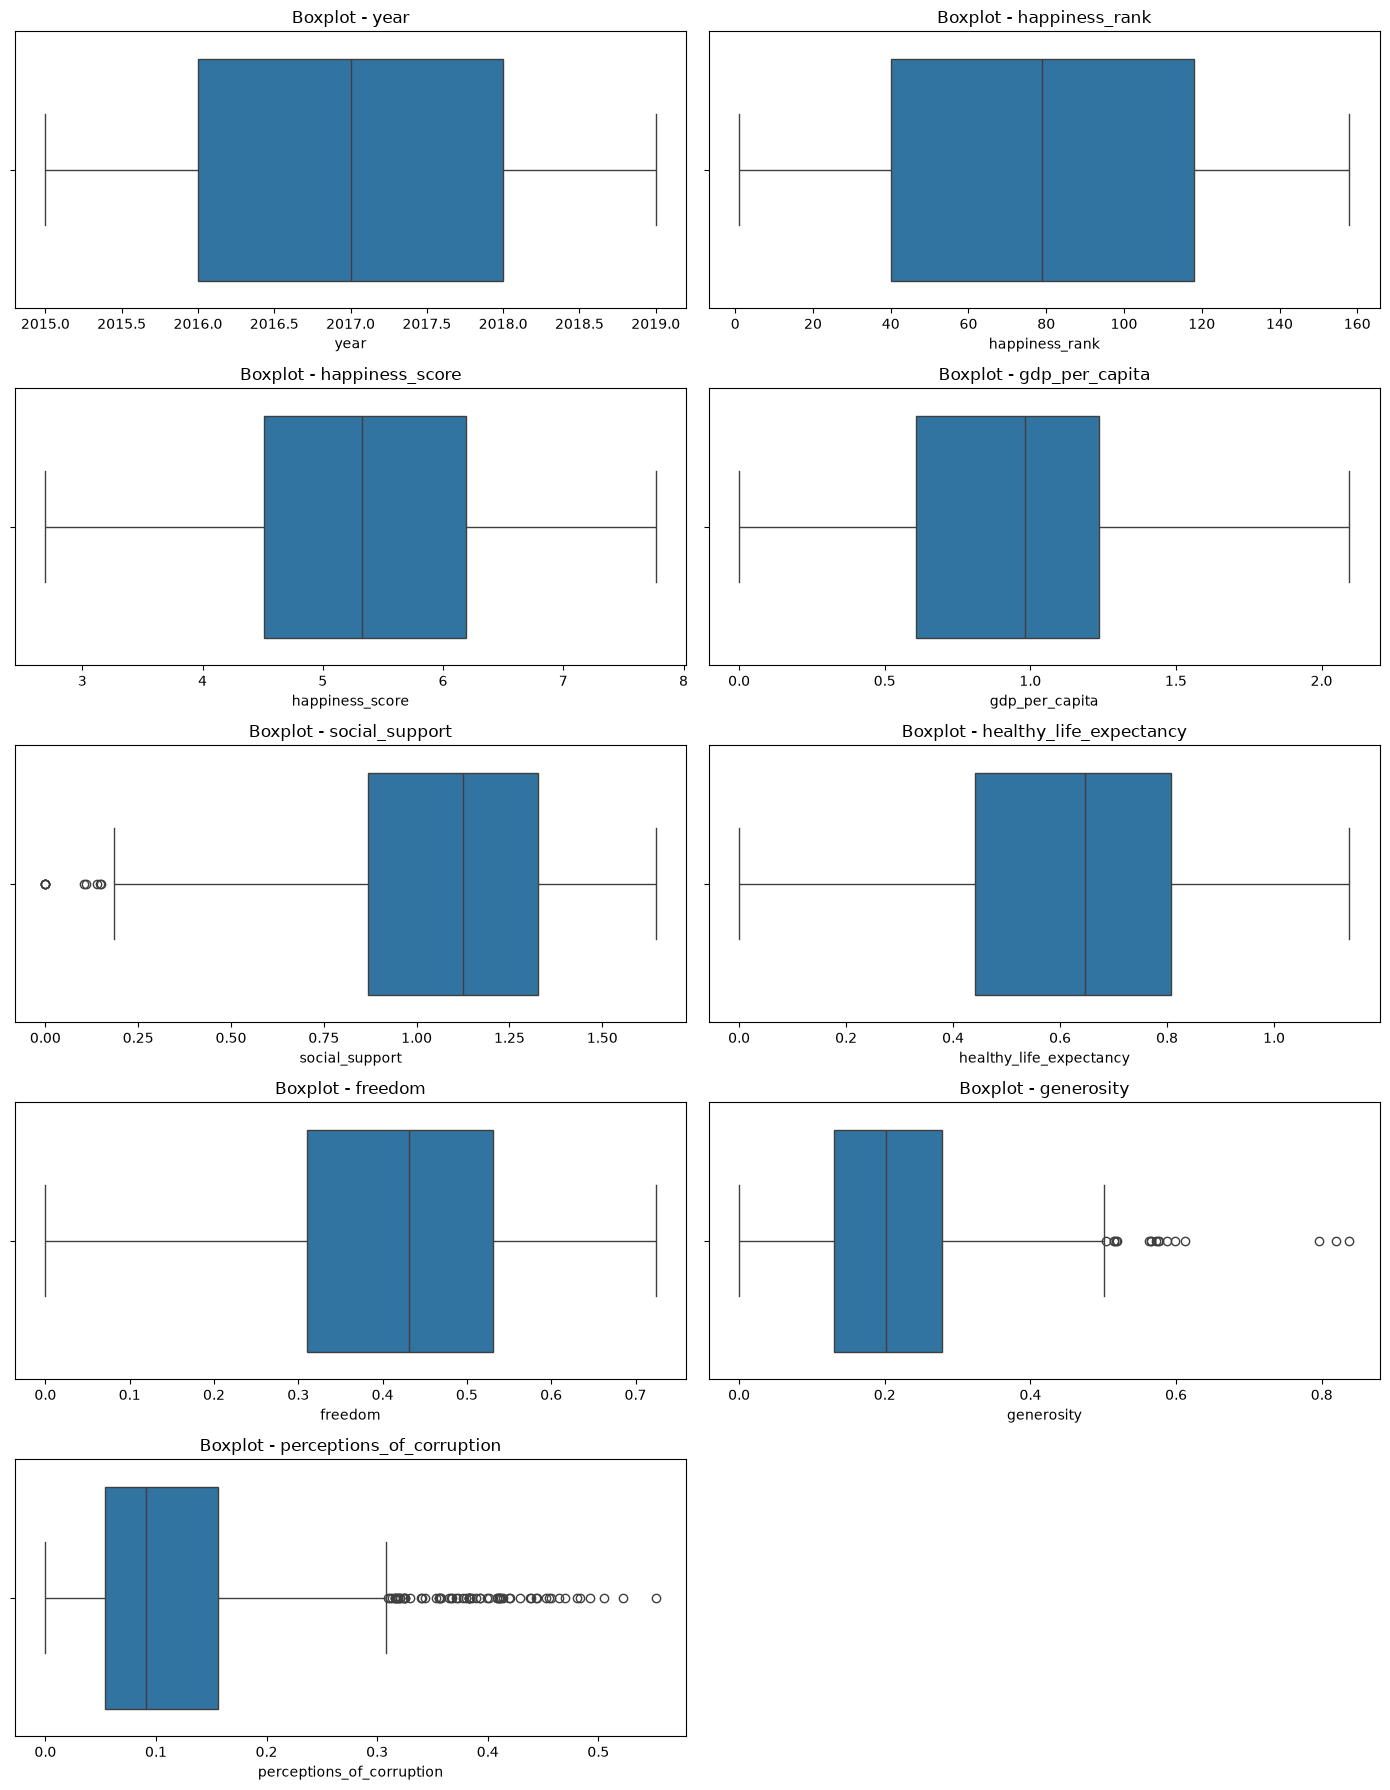

In [81]:

import matplotlib.pyplot as plt
import seaborn as sns

# Select numerical variables
columns = numeric_df.columns.tolist()

# Create boxplots
fig, axes = plt.subplots(
    nrows=5,
    ncols=2,
    figsize=(14, 18)
)

axes = axes.flatten()

for column, ax in zip(columns, axes):
    sns.boxplot(
        x=numeric_df[column],
        ax=ax
    )
    ax.set_title(f"Boxplot - {column}")

# Remove unused axes
for ax in axes[len(columns):]:
    ax.remove()

plt.tight_layout()
plt.show()

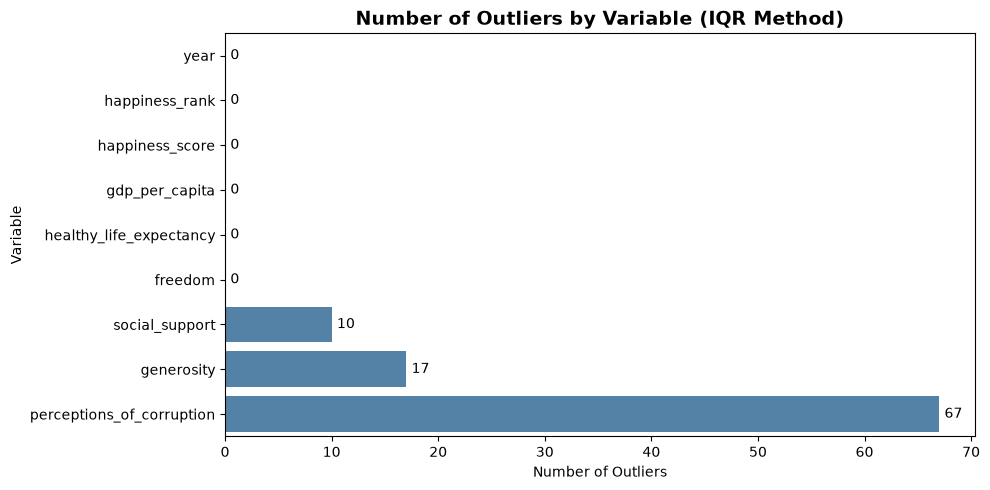

In [82]:
import matplotlib.pyplot as plt
import seaborn as sns

# Prepare data
outlier_counts = outlier_summary[
    "Potential Outliers"
].sort_values(ascending=True)

# Create chart
plt.figure(figsize=(10, 5))

sns.barplot(
    x=outlier_counts.values,
    y=outlier_counts.index,
    color="steelblue"
)

plt.title(
    "Number of Outliers by Variable (IQR Method)",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Number of Outliers")
plt.ylabel("Variable")

# Display values on bars
for i, value in enumerate(outlier_counts.values):
    plt.text(value + 0.5, i, str(value), va="center")

plt.tight_layout()
plt.show()

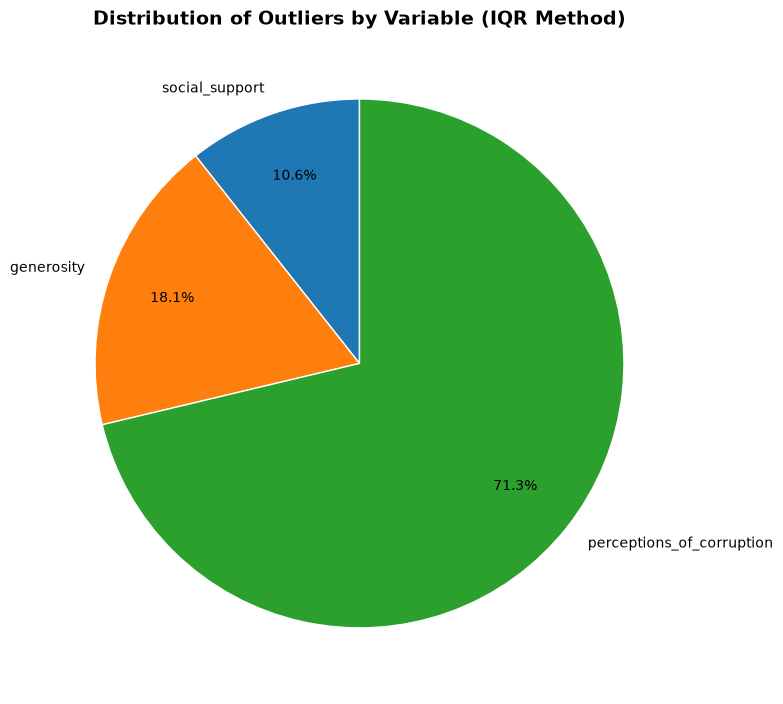

In [83]:

import matplotlib.pyplot as plt

# Prepare data
outlier_counts = outlier_summary["Potential Outliers"]
outlier_counts = outlier_counts[outlier_counts > 0]

# Create pie chart
plt.figure(figsize=(8, 8))

plt.pie(
    outlier_counts.values,
    labels=outlier_counts.index,
    autopct="%1.1f%%",
    startangle=90,
    pctdistance=0.75,
    wedgeprops={"edgecolor": "white", "linewidth": 1}
)

plt.title(
    "Distribution of Outliers by Variable (IQR Method)",
    fontsize=14,
    fontweight="bold"
)

plt.tight_layout()
plt.show()


In [84]:

# Identify potential outliers in perceptions_of_corruption

Q1 = happiness_df["perceptions_of_corruption"].quantile(0.25)
Q3 = happiness_df["perceptions_of_corruption"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

corruption_outliers = happiness_df[
    (happiness_df["perceptions_of_corruption"] < lower_bound) |
    (happiness_df["perceptions_of_corruption"] > upper_bound)
]

# Display all columns without truncating rows
with pd.option_context("display.max_rows", None):
    display(
        corruption_outliers[
            ["country", "year", "perceptions_of_corruption"]
        ].sort_values("perceptions_of_corruption")
    )


,country,year,perceptions_of_corruption
641,Ireland,2019,0.310000
233,Somalia,2016,0.311800
163,Canada,2016,0.313290
315,Norway,2017,0.315964
639,Luxembourg,2019,0.316000
232,Hong Kong,2016,0.316470
6,Netherlands,2015,0.318140
283,Georgia,2016,0.318800
332,Luxembourg,2017,0.318834
20,United Kingdom,2015,0.320670


## 1. Model Decision Table

| Model | Outlier Treatment | Feature Scaling | Justification |
|---|---|---|---|
| **Linear Regression** | Evaluate their influence and test Winsorization. | Yes, recommended. | Sensitive to extreme values because they can influence regression coefficients. Standardization also helps place numerical features on comparable scales. |
| **Random Forest Regressor** | Initially retain outliers. | Not required. | Tree-based models use threshold-based splits and do not require features to have similar scales. |
| **Decision Tree Regressor** | Initially retain outliers. | Not required. | Decision tree splits are based on feature thresholds and are independent of feature scales. |